# Linux 지원 Steam 게임 개인화 추천 — 기초 EDA

- **A (학습)**: Steam 추천 리뷰 데이터, Game Recommendations on Steam (`antonkozyriev/game-recommendations-on-steam`)
- **B (외부 평가)**: Steam 보유 게임·리뷰 데이터, Steam Video Game and Bundle Data (`pypiahmad/steam-video-game-and-bundle-data`, UCSD McAuley 데이터 복제본)
- **C (보조 게임 정보)**: Steam Games Dataset 2025 (`artermiloff/steam-games-dataset`, `games_march2025_cleaned.csv`)

이 노트북에서 쓰는 말
- **평가용 정답(target)**: 사용자가 긍정적으로 리뷰한 게임. 평가할 때 정답으로 숨겨 둔다.
- **입력(input)**: 정답을 맞힐 때 취향을 파악하기 위해 사용하는 보유·플레이 이력이다.
- **k-core**: 사용자와 게임별 긍정 리뷰 수 기준을 반복 적용해, 기준을 만족하지 못하는 데이터 행을 걸러 낸 결과다.
- **CCDF(보완 누적 분포)**: 가로축에 표시한 개수 이상을 가진 사용자·게임의 비율이다.
- **대체 추천(fallback)**: 개인화 추천을 만들 수 없을 때 대신 보여 주는 추천이다.
- **협업 필터링(CF)**: 비슷한 사용자나 게임의 리뷰 이력을 이용하는 추천 방식이다.
- **ALS**: 사용자와 게임의 취향을 숫자 벡터로 요약해 협업 필터링을 하는 방식이다.

다시 실행하는 순서 (EDA/ 폴더 기준)
1. [EDA README의 재현 방법](../README.md#재현-방법)에 따라 공식 Kaggle 도구로 원본을 내려받는다.
2. `python -I scripts/preprocess.py`를 실행해 원본을 `data/processed/*.parquet`로 변환한다. 형식만 바꾸며 행은 삭제하지 않는다.
3. `python scripts/build_notebook.py`를 실행해 이 노트북을 만들고 실행한다.

이 노트북에서 계산한 수치는 `reports/eda_metrics.json`과 `reports/tables/*.csv`에 저장된다.
데이터셋마다 사용자 ID 체계가 다르므로, 서로 다른 데이터의 ID가 같은 사람을 뜻한다고 가정하지 않는다. 게임은 Steam App ID로만 연결한다.

In [1]:
import json
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter
import pandas as pd
from scipy import stats

EDA = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(EDA / "scripts"))
from readable_labels import display_readable as display, setup_korean_font

P, FIG, REP = EDA / "data" / "processed", EDA / "figures", EDA / "reports"
TAB = REP / "tables"
for d in (FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

RESULTS = {}


def _py(v):
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, (np.floating,)):
        return float(v)
    if isinstance(v, (np.bool_,)):
        return bool(v)
    if isinstance(v, pd.Timestamp):
        return v.isoformat()
    if isinstance(v, dict):
        return {k: _py(x) for k, x in v.items()}
    if isinstance(v, (list, tuple)):
        return [_py(x) for x in v]
    return v


def rec(key, value):
    """계산된 수치를 RESULTS에 기록하고 그대로 반환."""
    RESULTS[key] = _py(value)
    return value


def save_table(df, name, index=False):
    df.to_csv(TAB / f"{name}.csv", index=index, encoding="utf-8-sig")
    return df


# 차트 모양: 범주 색상은 파랑 → 주황 → 청록 순서로 고정하고, 선과 격자는 가늘고 연하게 표시한다.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW]),
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "legend.frameon": False,
})
assert setup_korean_font(), "그래프에 쓸 한글 글꼴을 찾지 못했다."


def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")


def plain_log_ticks(axis):
    """로그 축의 1보다 작은 눈금을 10의 거듭제곱 대신 0.01처럼 표시한다. 한글 글꼴에는 수식용 빼기 기호가 없다."""
    axis.set_major_formatter(FuncFormatter(lambda v, _: np.format_float_positional(v, trim="-")))


def ccdf(ax, counts, label, color=None):
    """개수가 x 이상일 비율을 양쪽 로그 축의 계단선으로 표시한다."""
    v = np.sort(np.asarray(counts))
    x, idx = np.unique(v, return_index=True)
    y = 1 - idx / len(v)
    ax.step(x, y, where="post", label=label, color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")
    plain_log_ticks(ax.yaxis)


def qtable(s, qs=(0.25, 0.5, 0.75, 0.9, 0.99)):
    return {f"p{int(q * 100)}": float(s.quantile(q)) for q in qs} | {"mean": float(s.mean()), "max": float(s.max())}

## 0. 데이터 출처·버전·파일 크기

In [2]:
manifest = json.loads((EDA / "data" / "raw" / "manifest.json").read_text("utf-8"))
src_rows = []
for k, v in manifest.items():
    for f in v["files"]:
        src_rows.append({"dataset": k, "kaggle_ref": v["ref"], "kaggle_version": v["kaggle_version"],
                         "kaggle_last_updated": v["kaggle_last_updated"][:10], "license": v["license"],
                         "file": f["kaggle_file"], "MB": round(f["local_bytes"] / 1e6, 1),
                         "partial_download": bool(f["partial_head_bytes"]), "downloaded_at": v["downloaded_at_utc"][:10]})
sources = save_table(pd.DataFrame(src_rows).sort_values(["dataset", "file"]), "00_sources")
display(sources)

,자료 이름,Kaggle 자료 주소,Kaggle 자료 버전,Kaggle 자료의 마지막 갱신일,이용 허가 조건,파일 이름,파일 크기(MB),일부만 내려받은 파일 여부,다운로드 날짜
6,A 자료,antonkozyriev/game-recommendations-on-steam,28,2024-08-14,CC0: Public Domain,games.csv,4.9000,아니요,2026-11-03
7,A 자료,antonkozyriev/game-recommendations-on-steam,28,2024-08-14,CC0: Public Domain,games_metadata.json,17.5000,아니요,2026-11-03
9,A 자료,antonkozyriev/game-recommendations-on-steam,28,2024-08-14,CC0: Public Domain,recommendations.csv,"2,023.2000",아니요,2026-11-03
8,A 자료,antonkozyriev/game-recommendations-on-steam,28,2024-08-14,CC0: Public Domain,users.csv,193.1000,아니요,2026-11-03
0,B 자료,pypiahmad/steam-video-game-and-bundle-data,1,2023-10-29,Apache 2.0,australian_user_reviews.json,26.3000,아니요,2026-11-03
1,B 자료,pypiahmad/steam-video-game-and-bundle-data,1,2023-10-29,Apache 2.0,australian_users_items.json,553.1000,아니요,2026-11-03
3,B 자료,pypiahmad/steam-video-game-and-bundle-data,1,2023-10-29,Apache 2.0,bundle_data.json,0.8000,아니요,2026-11-03
2,B 자료,pypiahmad/steam-video-game-and-bundle-data,1,2023-10-29,Apache 2.0,steam_games.json,21.2000,아니요,2026-11-03
4,B 자료,pypiahmad/steam-video-game-and-bundle-data,1,2023-10-29,Apache 2.0,steam_reviews.json/steam_new.json,67.1000,예,2026-11-03
5,C 자료,artermiloff/steam-games-dataset,2,2025-03-13,MIT,games_march2025_cleaned.csv,468.6000,아니요,2026-11-03


## 1. 데이터 구조 — 행 수, 열 이름, 자료형, 빈 값, 중복

In [3]:
A_rec = pd.read_parquet(P / "A_recommendations.parquet")
A_games = pd.read_parquet(P / "A_games.parquet")
A_users = pd.read_parquet(P / "A_users.parquet")
A_meta = pd.read_parquet(P / "A_games_metadata.parquet")
B_prof = pd.read_parquet(P / "B_users_items_profiles.parquet")
B_items = pd.read_parquet(P / "B_users_items.parquet")
B_rev = pd.read_parquet(P / "B_reviews.parquet")
B_sg = pd.read_parquet(P / "B_steam_games.parquet")
B_bun = pd.read_parquet(P / "B_bundle_items.parquet")
C = pd.read_parquet(P / "C_games_2025.parquet")

tables = {"A_recommendations": A_rec, "A_games": A_games, "A_users": A_users, "A_games_metadata": A_meta,
          "B_users_items(profile)": B_prof, "B_users_items(long)": B_items, "B_reviews(long)": B_rev,
          "B_steam_games": B_sg, "B_bundle_items(long)": B_bun, "C_games_2025": C}

schema = pd.concat([
    pd.DataFrame({"table": n, "column": df.columns, "dtype": df.dtypes.astype(str).values,
                  "n_null": df.isna().sum().values, "null_pct": (df.isna().mean() * 100).round(3).values})
    for n, df in tables.items()])
save_table(schema, "01_schema_nulls")
display(schema[schema.n_null > 0])

,표 이름,원본 열 이름,자료형,결측값 수,"결측 비율(전체 행 중, %)"
11,B_reviews(long),posted_date,datetime64[us],10119,17.0630
0,B_steam_games,id_raw,str,2,0.0060
1,B_steam_games,app_name,str,2,0.0060
2,B_steam_games,title,str,2050,6.3790
3,B_steam_games,release_date,str,2067,6.4320
4,B_steam_games,genres,object,3283,10.2160
5,B_steam_games,tags,object,163,0.5070
6,B_steam_games,specs,object,670,2.0850
7,B_steam_games,price,str,1377,4.2850
9,B_steam_games,developer,str,3299,10.2660


In [4]:
def n_dup(df, cols):
    return int(df.duplicated(cols).sum())


structure = pd.DataFrame([
    dict(table="A_recommendations", rows=len(A_rec), cols=A_rec.shape[1], users=A_rec.user_id.nunique(),
         items=A_rec.app_id.nunique(), dup_key="user_id+app_id", dup_rows=n_dup(A_rec, ["user_id", "app_id"]),
         date_min=A_rec.date.min(), date_max=A_rec.date.max()),
    dict(table="A_games", rows=len(A_games), cols=A_games.shape[1], items=A_games.app_id.nunique(),
         dup_key="app_id", dup_rows=n_dup(A_games, ["app_id"]),
         date_min=A_games.date_release.min(), date_max=A_games.date_release.max()),
    dict(table="A_users", rows=len(A_users), cols=A_users.shape[1], users=A_users.user_id.nunique(),
         dup_key="user_id", dup_rows=n_dup(A_users, ["user_id"])),
    dict(table="A_games_metadata", rows=len(A_meta), cols=A_meta.shape[1], items=A_meta.app_id.nunique(),
         dup_key="app_id", dup_rows=n_dup(A_meta, ["app_id"])),
    dict(table="B_users_items(profile)", rows=len(B_prof), cols=B_prof.shape[1], users=B_prof.user_id.nunique(),
         dup_key="user_id", dup_rows=n_dup(B_prof, ["user_id"])),
    dict(table="B_users_items(long)", rows=len(B_items), cols=B_items.shape[1], users=B_items.user_id.nunique(),
         items=B_items.item_id.nunique(), dup_key="user_id+item_id", dup_rows=n_dup(B_items, ["user_id", "item_id"])),
    dict(table="B_reviews(long)", rows=len(B_rev), cols=B_rev.shape[1], users=B_rev.user_id.nunique(),
         items=B_rev.item_id.nunique(), dup_key="user_id+item_id", dup_rows=n_dup(B_rev, ["user_id", "item_id"]),
         date_min=B_rev.posted_date.min(), date_max=B_rev.posted_date.max()),
    dict(table="B_steam_games", rows=len(B_sg), cols=B_sg.shape[1], items=B_sg.id.nunique(),
         dup_key="id", dup_rows=n_dup(B_sg.dropna(subset=["id"]), ["id"])),
    dict(table="B_bundle_items(long)", rows=len(B_bun), cols=B_bun.shape[1], items=B_bun.item_id.nunique(),
         dup_key="bundle_id+item_id", dup_rows=n_dup(B_bun, ["bundle_id", "item_id"])),
    dict(table="C_games_2025", rows=len(C), cols=C.shape[1], items=C.appid.nunique(),
         dup_key="appid", dup_rows=n_dup(C, ["appid"])),
])
save_table(structure, "01_structure")
rec("structure", structure.astype(object).where(structure.notna(), None).to_dict("records"))
display(structure)

,표 이름,행 수,열 수,사용자 수,게임 항목 수,중복 확인 기준 열,중복 행 수,가장 이른 날짜,가장 늦은 날짜
0,A_recommendations,41154794,8,"13,781,059.0000","37,610.0000",user_id+app_id,21,2010-10-15,2022-12-31
1,A_games,50872,13,NaN,"50,872.0000",app_id,0,1997-06-30,2023-10-24
2,A_users,14306064,3,"14,306,064.0000",NaN,user_id,0,NaT,NaT
3,A_games_metadata,50872,3,NaN,"50,872.0000",app_id,0,NaT,NaT
4,B_users_items(profile),88310,5,"87,626.0000",NaN,user_id,684,NaT,NaT
5,B_users_items(long),5153209,7,"70,912.0000","10,978.0000",user_id+item_id,59127,NaT,NaT
6,B_reviews(long),59305,12,"25,458.0000","3,682.0000",user_id+item_id,874,2010-10-16,2015-12-31
7,B_steam_games,32135,14,NaN,"32,132.0000",id,1,NaT,NaT
8,B_bundle_items(long),3525,4,NaN,"2,787.0000",bundle_id+item_id,7,NaT,NaT
9,C_games_2025,89618,47,NaN,"89,618.0000",appid,0,NaT,NaT


### 1-1. 비어 있지만 결측으로 표시되지 않는 값과 B의 중복 프로필
`isna()`가 찾아내지 못하는 빈 태그 목록, 빈 설명, `"[]"`/`"{}"` 문자열도 따로 센다.

In [5]:
empty = {
    "A_meta_tags_empty": int(A_meta.tags.map(len).eq(0).sum()),
    "A_meta_description_empty": int(A_meta.description.fillna("").str.strip().eq("").sum()),
    "B_steam_games_id_missing": int(B_sg.id.isna().sum()),
    "B_steam_games_tags_missing": int(B_sg.tags.isna().sum()),
    "B_steam_games_genres_missing": int(B_sg.genres.isna().sum()),
    "C_tags_empty": int(C.tags.fillna("{}").isin(["{}", "[]", ""]).sum()),
    "C_genres_empty": int(C.genres.fillna("[]").isin(["[]", ""]).sum()),
    "C_short_description_empty": int(C.short_description.fillna("").str.strip().eq("").sum()),
}
rec("empty_values", empty)

# B: 같은 `user_id`가 여러 프로필 행에 나타나는지와, 그 행들의 게임 목록이 같은지 확인한다.
dup_users = B_prof.user_id[B_prof.user_id.duplicated(keep=False)].unique()
sig = (B_items[B_items.user_id.isin(dup_users)]
       .groupby("line_no").item_id.agg(lambda s: hash(tuple(sorted(s.tolist())))))
sig = B_prof.set_index("line_no").loc[B_prof.line_no[B_prof.user_id.isin(dup_users)], ["user_id"]].join(sig.rename("sig"))
sig["sig"] = sig["sig"].fillna(0)
identical = sig.groupby("user_id").sig.nunique().eq(1)
rec("B_profile_duplicates", {"profile_lines": len(B_prof), "unique_users": B_prof.user_id.nunique(),
                             "users_with_dup_lines": len(dup_users),
                             "dup_users_identical_item_lists": int(identical.sum())})

rev_lines = B_rev.groupby("user_id").line_no.nunique()
conflict = B_rev.dropna(subset=["item_id"]).groupby(["user_id", "item_id"]).recommend.nunique().gt(1)
rec("B_review_duplicates", {"users_with_multiple_review_lines": int(rev_lines.gt(1).sum()),
                            "dup_user_item_rows": n_dup(B_rev, ["user_id", "item_id"]),
                            "user_item_with_conflicting_label": int(conflict.sum())})
rec("A_users_consistency", {
    "rec_users_missing_in_users_csv": int((~pd.Index(A_rec.user_id.unique()).isin(A_users.user_id)).sum()),
    "rec_items_missing_in_games_csv": int((~pd.Index(A_rec.app_id.unique()).isin(A_games.app_id)).sum()),
    "games_without_any_rec": int((~A_games.app_id.isin(A_rec.app_id.unique())).sum()),
    "games_metadata_ids_equal_games_ids": bool(set(A_meta.app_id) == set(A_games.app_id)),
})
display({k: RESULTS[k] for k in ["empty_values", "B_profile_duplicates", "B_review_duplicates", "A_users_consistency"]})

,항목,값
0,비어 있는 값 / A에서 태그가 빈 게임 수,"1,244"
1,비어 있는 값 / A에서 설명이 빈 게임 수,"10,373"
2,비어 있는 값 / B 게임 목록에서 ID가 없는 행 수,2
3,비어 있는 값 / B 게임 목록에서 태그가 없는 행 수,163
4,비어 있는 값 / B 게임 목록에서 장르가 없는 행 수,"3,283"
5,비어 있는 값 / C에서 태그가 빈 게임 수,"16,872"
6,비어 있는 값 / C에서 장르가 빈 게임 수,212
7,비어 있는 값 / C에서 짧은 설명이 빈 게임 수,120
8,B 프로필 중복 / 프로필 행 수,"88,310"
9,B 프로필 중복 / 서로 다른 사용자 수,"87,626"


## 2. 데이터셋 A — 리뷰 데이터 품질
A에는 추천 또는 비추천으로 남긴 리뷰만 있다. 게임을 보유했지만 리뷰하지 않은 기록은 포함되지 않는다.
`hours`는 리뷰를 작성할 당시까지의 플레이 시간이다.

In [6]:
u_cnt = A_rec.groupby("user_id").size()
i_cnt = A_rec.groupby("app_id").size()
A_pos = A_rec[A_rec.is_recommended]
u_pos = A_pos.groupby("user_id").size()
i_pos = A_pos.groupby("app_id").size()

n_u, n_i, n = A_rec.user_id.nunique(), A_rec.app_id.nunique(), len(A_rec)
rec("A_quality", {
    "interactions": n, "users": n_u, "items": n_i,
    "positive_rate": float(A_rec.is_recommended.mean()),
    "density": n / (n_u * n_i), "sparsity": 1 - n / (n_u * n_i),
    "per_user": qtable(u_cnt), "per_item": qtable(i_cnt),
    "users_with_1_review_pct": float((u_cnt == 1).mean() * 100),
    "users_with_ge5_reviews_pct": float((u_cnt >= 5).mean() * 100),
    "users_with_ge10_reviews_pct": float((u_cnt >= 10).mean() * 100),
    "users_with_ge5_positive_pct": float((u_pos.reindex(u_cnt.index, fill_value=0) >= 5).mean() * 100),
    "users_with_no_positive_pct": float((~u_cnt.index.isin(u_pos.index)).mean() * 100),
    "items_with_ge10_positive": int((i_pos >= 10).sum()),
    "items_with_ge50_positive": int((i_pos >= 50).sum()),
    "hours": qtable(A_rec.hours),
    "hours_zero_pct": float((A_rec.hours == 0).mean() * 100),
    "hours_at_cap_1000_pct": float((A_rec.hours >= 1000).mean() * 100),
    "hours_median_pos": float(A_rec.hours[A_rec.is_recommended].median()),
    "hours_median_neg": float(A_rec.hours[~A_rec.is_recommended].median()),
})
display(RESULTS["A_quality"])

,항목,값
0,사용자-게임 상호작용 수,"41,154,794"
1,사용자 수,"13,781,059"
2,게임 항목 수,"37,610"
3,긍정 리뷰 비율(0~1),0.8578
4,"행렬 밀도(비어 있지 않은 칸 비율, 0~1)",0.0001
5,"행렬 희소도(빈 칸 비율, 0~1)",0.9999
6,사용자별 / 하위 25% 값,1
7,사용자별 / 중앙값,1
8,사용자별 / 하위 75% 값,3
9,사용자별 / 하위 90% 값,6


In [7]:
# `users.csv`의 공개 프로필에 기록된 리뷰·제품 수를 실제 추천 리뷰 수와 비교한다.
uc = A_users.set_index("user_id").join(u_cnt.rename("rec_rows"), how="inner")
rec("A_users_csv_vs_rec", {
    "users_joined": len(uc),
    "reviews_col_equals_rec_rows_pct": float((uc.reviews == uc.rec_rows).mean() * 100),
    "products_median": float(uc.products.median()),
    "reviews_to_products_median_ratio": float((uc.rec_rows / uc.products.replace(0, np.nan)).median()),
    "users_csv_users_with_0_reviews_pct": float((A_users.reviews == 0).mean() * 100),
})
display(RESULTS["A_users_csv_vs_rec"])

,항목,값
0,두 파일로 연결한 사용자 수,"13,781,059"
1,사용자 파일의 리뷰 수와 실제 리뷰 행 수가 같은 비율(%),100
2,사용자별 보유 제품 수 중앙값,57
3,보유 제품 대비 리뷰 수 비율의 중앙값,0.0326
4,사용자 파일에서 리뷰 수가 0인 사용자 비율(%),3.6698


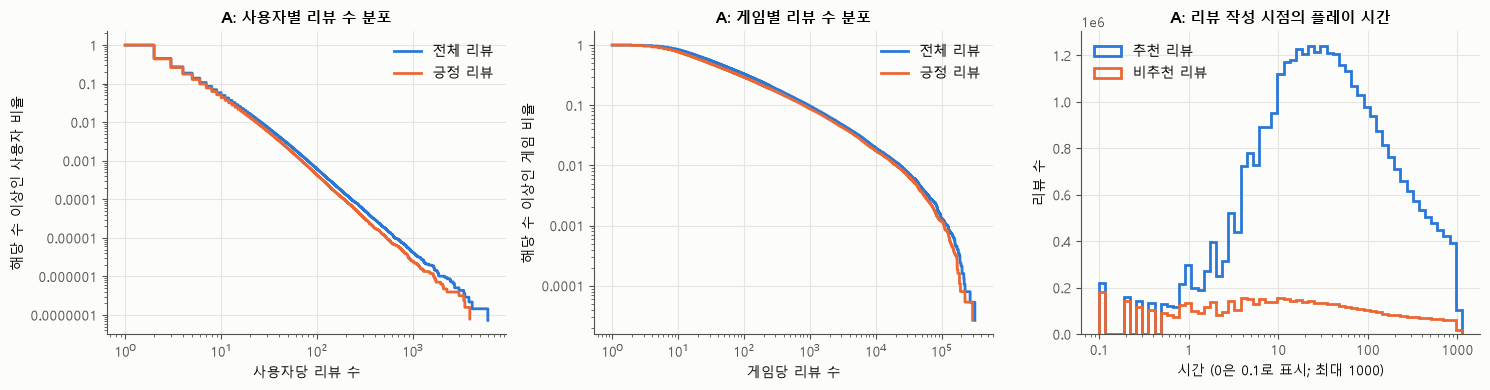

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ccdf(axes[0], u_cnt.values, "전체 리뷰")
ccdf(axes[0], u_pos.values, "긍정 리뷰")
axes[0].set(title="A: 사용자별 리뷰 수 분포", xlabel="사용자당 리뷰 수", ylabel="해당 수 이상인 사용자 비율")
axes[0].legend()
ccdf(axes[1], i_cnt.values, "전체 리뷰")
ccdf(axes[1], i_pos.values, "긍정 리뷰")
axes[1].set(title="A: 게임별 리뷰 수 분포", xlabel="게임당 리뷰 수", ylabel="해당 수 이상인 게임 비율")
axes[1].legend()
bins = np.logspace(-1, 3.05, 60)
axes[2].hist(A_rec.hours[A_rec.is_recommended].clip(lower=0.1), bins=bins, histtype="step", lw=2, label="추천 리뷰")
axes[2].hist(A_rec.hours[~A_rec.is_recommended].clip(lower=0.1), bins=bins, histtype="step", lw=2, label="비추천 리뷰")
axes[2].set(xscale="log", title="A: 리뷰 작성 시점의 플레이 시간", xlabel="시간 (0은 0.1로 표시; 최대 1000)", ylabel="리뷰 수")
plain_log_ticks(axes[2].xaxis)
axes[2].legend()
fig.tight_layout()
save_fig(fig, "fig01_A_interactions_hours")

,A 리뷰 수,"A 리뷰의 긍정 비율(A 리뷰 중, 0~1)",날짜 정보가 있는 B 리뷰 수
연도,,,
"2,010.0000",12201,0.9739,66.0000
"2,011.0000",71546,0.9650,532.0000
"2,012.0000",101726,0.9599,"1,215.0000"
"2,013.0000",335335,0.9307,"6,792.0000"
"2,014.0000",1143156,0.8796,"22,111.0000"
"2,015.0000",1477099,0.8347,"18,470.0000"
"2,016.0000",2226413,0.8349,NaN
"2,017.0000",2834442,0.8221,NaN
"2,018.0000",2845219,0.8132,NaN


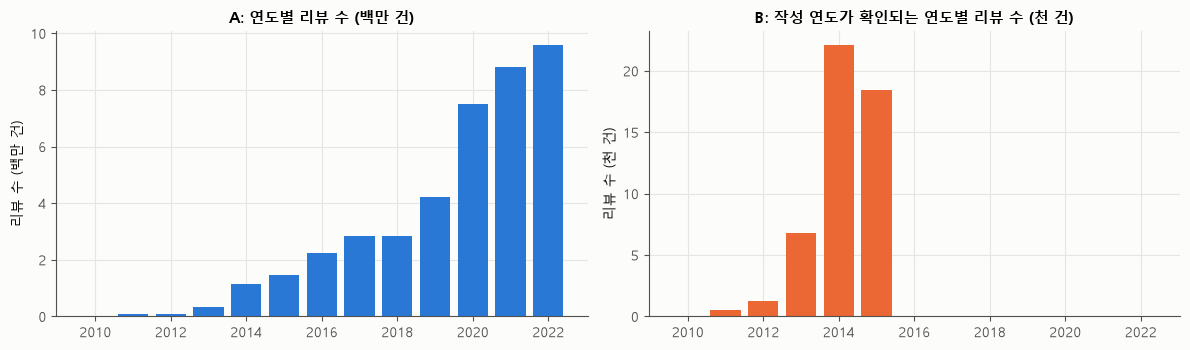

In [9]:
yearly = pd.DataFrame({
    "A_reviews": A_rec.groupby(A_rec.date.dt.year).size(),
    "A_positive_rate": A_rec.groupby(A_rec.date.dt.year).is_recommended.mean(),
    "B_reviews_dated": B_rev.groupby(B_rev.posted_date.dt.year).size(),
}).rename_axis("year")
save_table(yearly.reset_index(), "02_reviews_by_year")
rec("A_reviews_le_2015", int((A_rec.date <= "2015-12-31").sum()))
rec("B_review_dates", {"with_year": int(B_rev.posted_has_year.sum()), "without_year": int((~B_rev.posted_has_year).sum()),
                       "min": B_rev.posted_date.min(), "max": B_rev.posted_date.max()})

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharex=True)
axes[0].bar(yearly.index, yearly.A_reviews.fillna(0) / 1e6, color=BLUE, width=0.8)
axes[0].set(title="A: 연도별 리뷰 수 (백만 건)", ylabel="리뷰 수 (백만 건)")
axes[1].bar(yearly.index, yearly.B_reviews_dated.fillna(0) / 1e3, color=ORANGE, width=0.8)
axes[1].set(title="B: 작성 연도가 확인되는 연도별 리뷰 수 (천 건)", ylabel="리뷰 수 (천 건)")
fig.tight_layout()
save_fig(fig, "fig02_reviews_by_year")
display(yearly)

In [10]:
# k-core: 사용자별·게임별 최소 긍정 리뷰 수를 번갈아 적용하며, 기준을 못 채우는 행을 반복해서 제외한다.
def kcore(df, ku, ki, max_iter=30):
    for _ in range(max_iter):
        before = len(df)
        df = df[df.groupby("app_id").user_id.transform("size") >= ki]
        df = df[df.groupby("user_id").app_id.transform("size") >= ku]
        if len(df) == before:
            break
    return df


lin_ids = set(A_games.app_id[A_games.linux])
pos_pairs = A_pos[["user_id", "app_id"]]
kc_rows = []
for ku, ki in [(1, 1), (2, 5), (3, 10), (5, 10), (5, 20), (10, 20)]:
    k = kcore(pos_pairs, ku, ki)
    nu, ni = k.user_id.nunique(), k.app_id.nunique()
    kc_rows.append({"min_user_pos": ku, "min_item_pos": ki, "users": nu, "items": ni, "interactions": len(k),
                    "density": len(k) / (nu * ni), "linux_items": len(set(k.app_id.unique()) & lin_ids),
                    "linux_interactions": int(k.app_id.isin(lin_ids).sum())})
kcore_tab = save_table(pd.DataFrame(kc_rows), "02_A_positive_kcore")
rec("A_positive_kcore", kc_rows)
display(kcore_tab)

,사용자별 최소 긍정 리뷰 수 기준,게임별 최소 긍정 리뷰 수 기준,사용자 수,게임 항목 수,사용자-게임 상호작용 수,"행렬 밀도(비어 있지 않은 칸 비율, 0~1)",Linux 게임 항목 수,Linux 사용자-게임 상호작용 수
0,1,1,12663134,37419,35304398,0.0001,6618,10428788
1,2,5,5547226,33148,28177261,0.0002,6142,8365174
2,3,10,3301339,27045,23644909,0.0003,5328,7079408
3,5,10,1621480,26064,17986052,0.0004,5195,5442255
4,5,20,1617467,19688,17882168,0.0006,4267,5424688
5,10,20,543517,17916,11021839,0.0011,3975,3391453


## 3. Linux 지원 게임 분포
공식 Linux 지원 여부는 A의 `games.csv`에 있는 `linux` 값으로 판단한다. 이 값을 C(2025-03)의 값과 비교한다.

In [11]:
A_rec["is_linux"] = A_rec.app_id.isin(lin_ids)
lin_pos = A_rec[A_rec.is_linux & A_rec.is_recommended]
lin_pos_item = lin_pos.groupby("app_id").size().sort_values(ascending=False)
lin_pos_user = lin_pos.groupby("user_id").size()
lin_games = A_games[A_games.linux]

top_share = lambda s, f: float(s.iloc[: max(1, int(len(s) * f))].sum() / s.sum())
rec("A_linux", {
    "games_total": len(A_games), "linux_games": len(lin_games),
    "linux_games_pct": len(lin_games) / len(A_games) * 100,
    "linux_games_with_any_review": int(lin_games.app_id.isin(A_rec.app_id.unique()).sum()),
    "linux_games_with_ge10_positive": int((lin_pos_item >= 10).sum()),
    "linux_games_with_ge50_positive": int((lin_pos_item >= 50).sum()),
    "linux_games_released_le_2015": int((lin_games.date_release <= "2015-12-31").sum()),
    "reviews_on_linux": int(A_rec.is_linux.sum()),
    "reviews_on_linux_pct": float(A_rec.is_linux.mean() * 100),
    "positive_reviews_on_linux": len(lin_pos),
    "positive_rate_linux": float(A_rec.is_recommended[A_rec.is_linux].mean()),
    "positive_rate_non_linux": float(A_rec.is_recommended[~A_rec.is_linux].mean()),
    "users_with_ge1_linux_positive": len(lin_pos_user),
    "users_with_ge2_linux_positive": int((lin_pos_user >= 2).sum()),
    "users_with_ge5_linux_positive": int((lin_pos_user >= 5).sum()),
    "top1pct_linux_games_share_of_linux_positive": top_share(lin_pos_item, 0.01),
    "top10pct_linux_games_share_of_linux_positive": top_share(lin_pos_item, 0.10),
    "linux_positive_per_game": qtable(lin_pos_item),
    "linux_positive_reviews_le_2015": int((lin_pos.date <= "2015-12-31").sum()),
})
display(RESULTS["A_linux"])

,항목,값
0,전체 게임 수,"50,872"
1,Linux 게임 수,"9,041"
2,Linux 게임 비율(%),17.7721
3,리뷰가 있는 Linux 게임 수,"6,630"
4,긍정 리뷰가 10건 이상인 Linux 게임 수,"5,497"
5,긍정 리뷰가 50건 이상인 Linux 게임 수,"3,299"
6,2015년까지 출시된 Linux 게임 수,"2,101"
7,Linux 게임의 리뷰 수,"11,584,426"
8,Linux 게임의 리뷰 비율(%),28.1484
9,Linux 게임의 긍정 리뷰 수,"10,428,788"


In [12]:
ac = A_games[["app_id", "title", "linux", "date_release"]].merge(
    C[["appid", "name", "linux", "release_date"]].rename(columns={"appid": "app_id"}), on="app_id", how="inner",
    suffixes=("_A", "_C"))
flag_ct = pd.crosstab(ac.linux_A, ac.linux_C, rownames=["A linux (2024)"], colnames=["C linux (2025-03)"])
save_table(flag_ct, "03_linux_flag_A_vs_C", index=True)
rec("linux_flag_A_vs_C", {"common_games": len(ac), "agree_pct": float((ac.linux_A == ac.linux_C).mean() * 100),
                          "A_true_C_false": int((ac.linux_A & ~ac.linux_C).sum()),
                          "A_false_C_true": int((~ac.linux_A & ac.linux_C).sum())})
display(flag_ct)

,아니요,예
A 자료의 Linux 지원 여부(2024년 기준),,
아니요,NaN,NaN
예,NaN,NaN


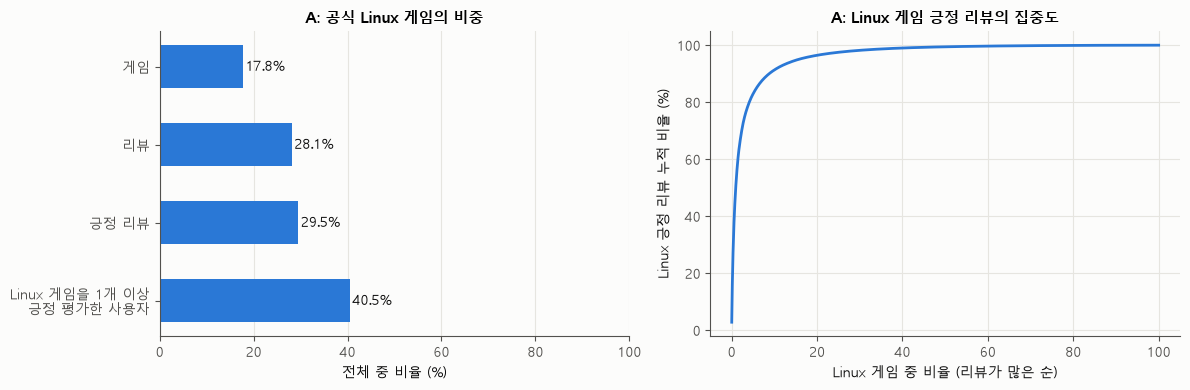

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
shares = pd.Series({
    "게임": RESULTS["A_linux"]["linux_games_pct"],
    "리뷰": RESULTS["A_linux"]["reviews_on_linux_pct"],
    "긍정 리뷰": len(lin_pos) / int(A_rec.is_recommended.sum()) * 100,
    "Linux 게임을 1개 이상\n긍정 평가한 사용자": len(lin_pos_user) / n_u * 100,
})
axes[0].barh(shares.index[::-1], shares.values[::-1], color=BLUE, height=0.55)
for y, v in enumerate(shares.values[::-1]):
    axes[0].text(v + 0.5, y, f"{v:.1f}%", va="center", color=INK)
axes[0].set(title="A: 공식 Linux 게임의 비중", xlabel="전체 중 비율 (%)", xlim=(0, 100))
axes[0].grid(axis="y", visible=False)
cum = lin_pos_item.cumsum() / lin_pos_item.sum()
axes[1].plot(np.arange(1, len(cum) + 1) / len(cum) * 100, cum.values * 100, color=BLUE)
axes[1].set(title="A: Linux 게임 긍정 리뷰의 집중도", xlabel="Linux 게임 중 비율 (리뷰가 많은 순)",
            ylabel="Linux 긍정 리뷰 누적 비율 (%)")
fig.tight_layout()
save_fig(fig, "fig03_A_linux_share_concentration")

## 4. 데이터셋 결합 — Steam App ID로 게임 연결
A의 `app_id`, B의 보유·리뷰 기록에 있는 `item_id`, B의 `steam_games.id`, C의 `appid`를 Steam App ID(정수)로 맞춰 연결한다.
B의 `item_id`는 원본에서 문자열이지만 모두 숫자로 변환되었다. 변환에 실패한 값은 없다(1장 참고).

In [14]:
S = {
    "A_games": set(A_games.app_id), "A_rec_items": set(A_rec.app_id.unique()), "A_linux": lin_ids,
    "C": set(C.appid), "C_linux": set(C.appid[C.linux == True]),
    "B_owned_items": set(B_items.item_id.dropna()), "B_review_items": set(B_rev.item_id.dropna()),
    "B_pos_review_items": set(B_rev.item_id[B_rev.recommend].dropna()), "B_steam_games": set(B_sg.id.dropna()),
}
ov_rows = []
for b in ["B_owned_items", "B_review_items", "B_pos_review_items", "B_steam_games"]:
    s = S[b]
    ov_rows.append({"B_set": b, "n": len(s),
                    "in_A_games": len(s & S["A_games"]), "in_A_games_pct": len(s & S["A_games"]) / len(s) * 100,
                    "in_A_rec_items": len(s & S["A_rec_items"]),
                    "in_A_linux": len(s & S["A_linux"]),
                    "in_C": len(s & S["C"]), "in_C_pct": len(s & S["C"]) / len(s) * 100,
                    "in_A_or_C": len(s & (S["A_games"] | S["C"])),
                    "in_neither": len(s - S["A_games"] - S["C"])})
overlap = save_table(pd.DataFrame(ov_rows), "04_id_overlap")
rec("id_overlap", ov_rows)
rec("A_C_overlap", {"A_games": len(S["A_games"]), "C": len(S["C"]), "A_and_C": len(S["A_games"] & S["C"]),
                    "A_not_in_C": len(S["A_games"] - S["C"]), "A_linux_in_C": len(S["A_linux"] & S["C"])})
display(overlap)

,B 항목 집합 이름,항목 수,A 게임 자료 포함 수,B 집합 게임 중 A 게임 자료에 포함된 비율(%),A 추천 대상 자료 포함 수,A Linux 게임 자료 포함 수,C 자료 포함 수,B 집합 게임 중 C 자료에 포함된 비율(%),A 또는 C 자료 포함 수,A와 C 어느 쪽에도 없는 수
0,B 보유 게임 항목,10978,7990,72.7819,7807,2274,7856,71.5613,8775,2203
1,B 리뷰 게임 항목,3682,2997,81.3960,2718,1023,2437,66.1869,3075,607
2,B 긍정 리뷰 게임 항목,3292,2706,82.1993,2462,943,2195,66.6768,2771,521
3,B Steam 게임 항목,32132,16214,50.4606,12598,4226,15112,47.0310,19493,12639


In [15]:
# 기록 건수 기준 비율: 서로 다른 게임 수가 아니라 B의 보유·리뷰 행 가운데 A에도 있는 게임의 비율을 센다.
bi_in_A = B_items.item_id.isin(S["A_games"])
br_in_A = B_rev.item_id.isin(S["A_games"])
rec("B_interaction_coverage_by_A", {
    "owned_rows_in_A_pct": float(bi_in_A.mean() * 100),
    "owned_rows_played_in_A_pct": float(bi_in_A[B_items.playtime_forever > 0].mean() * 100),
    "playtime_weighted_in_A_pct": float(B_items.playtime_forever[bi_in_A].sum() / B_items.playtime_forever.sum() * 100),
    "review_rows_in_A_pct": float(br_in_A.mean() * 100),
    "positive_review_rows_in_A_pct": float(br_in_A[B_rev.recommend].mean() * 100),
    "positive_review_rows_in_A_linux_pct": float(B_rev.item_id[B_rev.recommend].isin(lin_ids).mean() * 100),
})
display(RESULTS["B_interaction_coverage_by_A"])

,항목,값
0,B 보유 기록 중 A에 있는 비율(%),79.2893
1,B 플레이 기록 중 A에 있는 비율(%),83.6619
2,플레이 시간 기준 A에 있는 비율(%),87.9603
3,B 리뷰 중 A에 있는 비율(%),88.9487
4,B 긍정 리뷰 중 A에 있는 비율(%),90.2407
5,B 긍정 리뷰 중 A의 Linux 게임 비율(%),54.5442


In [16]:
# 목록 차이 살펴보기: B에서 보유한 게임 중 A에 없는 게임이 어떤 종류인지 이름으로 추정한다.
owners = B_items.drop_duplicates(["user_id", "item_id"]).groupby("item_id").agg(
    owners=("user_id", "size"), name=("item_name", "first"))
miss = owners[~owners.index.isin(S["A_games"])].copy()
patterns = {
    "server/SDK/tool": r"dedicated server|\bsdk\b|\btools?\b|editor|authoring|benchmark",
    "test/beta/demo": r"\btest\b|\bbeta\b|\bdemo\b|playtest|public test|\bpts\b",
    "soundtrack/video": r"soundtrack|\bost\b|artbook|movie|video|wallpaper",
    "dlc/pack": r"\bdlc\b|season pass|\bpack\b|expansion|bundle",
}
miss["reason_guess"] = "other"
for lab, pat in patterns.items():
    m = miss.reason_guess.eq("other") & miss.name.fillna("").str.contains(pat, case=False, regex=True)
    miss.loc[m, "reason_guess"] = lab
miss["in_C"] = miss.index.isin(S["C"])
miss["in_B_steam_games"] = miss.index.isin(S["B_steam_games"])
miss_summary = miss.groupby("reason_guess").agg(items=("owners", "size"), owner_rows=("owners", "sum"),
                                                in_C=("in_C", "sum"), in_B_steam_games=("in_B_steam_games", "sum"))
save_table(miss_summary.reset_index(), "04_B_owned_not_in_A_reasons")
rec("B_owned_not_in_A", {"items": len(miss), "owner_rows": int(miss.owners.sum()),
                         "median_owners": float(miss.owners.median()),
                         "median_owners_matched": float(owners.owners[owners.index.isin(S["A_games"])].median()),
                         "in_C": int(miss.in_C.sum()), "by_reason": miss_summary.reset_index().to_dict("records")})
save_table(miss.sort_values("owners", ascending=False).head(30).reset_index(), "04_B_owned_not_in_A_top30")
display(miss_summary)
display(miss.sort_values("owners", ascending=False).head(15))

,게임 항목 수,보유 기록 행 수,C 자료 포함 수,B Steam 게임 목록 포함 수
이름과 메타데이터로 추정한 분류,,,,
DLC·묶음 상품,NaN,NaN,<NA>,<NA>
기타,NaN,NaN,<NA>,<NA>
서버·개발 도구,NaN,NaN,<NA>,<NA>
사운드트랙·영상,NaN,NaN,<NA>,<NA>
테스트·베타·체험판,NaN,NaN,<NA>,<NA>


,보유자 수,게임 이름,이름과 메타데이터로 추정한 분류,C 자료 포함 수,B Steam 게임 목록 포함 수
게임 항목 ID,,,,,
205790,49136,Dota 2 Test,테스트·베타·체험판,아니요,아니요
223530,36661,Left 4 Dead 2 Beta,테스트·베타·체험판,아니요,아니요
72850,22038,The Elder Scrolls V: Skyrim,기타,예,아니요
208090,16309,Loadout,기타,아니요,예
232210,15740,Patch testing for Chivalry,기타,아니요,아니요
219540,14922,Arma 2: Operation Arrowhead Beta (Obsolete),테스트·베타·체험판,아니요,아니요
33910,14500,Arma 2,기타,아니요,아니요
243870,14449,Tom Clancy's Ghost Recon Phantoms - NA,기타,아니요,아니요
35420,13834,Killing Floor Mod: Defence Alliance 2,기타,아니요,예


In [17]:
# 게임 정보 비교: 두 데이터에 함께 있는 게임의 제목(간단히 표기 통일 후)과 출시일이 같은지 확인한다.
norm = lambda s: s.fillna("").str.lower().str.replace(r"[^0-9a-z]+", "", regex=True)
ac["title_match"] = norm(ac.title) == norm(ac.name)
ac["date_match"] = pd.to_datetime(ac.date_release).dt.date.astype(str) == ac.release_date.astype(str)
ab = A_games[["app_id", "title"]].merge(B_sg.dropna(subset=["id"]).drop_duplicates("id")[["id", "app_name"]]
                                        .rename(columns={"id": "app_id"}), on="app_id")
ab["title_match"] = norm(ab.title) == norm(ab.app_name)
rec("metadata_consistency", {"A_vs_C_title_match_pct": float(ac.title_match.mean() * 100),
                             "A_vs_C_release_date_match_pct": float(ac.date_match.mean() * 100),
                             "A_vs_B_steam_games_common": len(ab),
                             "A_vs_B_steam_games_title_match_pct": float(ab.title_match.mean() * 100)})
display(RESULTS["metadata_consistency"])

,항목,값
0,A와 C의 제목 일치 비율(%),98.7624
1,A와 C의 출시일 일치 비율(%),97.2154
2,A와 B 게임 목록의 공통 게임 수,"16,214"
3,A와 B 게임 목록의 제목 일치 비율(%),96.2317


In [18]:
# 게임 설명·태그를 쓰는 추천 방식에서 사용할 수 있는 텍스트 정보의 비율을 Linux 게임에 한해 확인한다.
lm = lin_games[["app_id"]].merge(A_meta, on="app_id", how="left").merge(
    C[["appid", "tags", "genres", "short_description"]].rename(columns={"appid": "app_id", "tags": "C_tags"}),
    on="app_id", how="left")
has_A_tags = lm.tags.map(lambda t: t is not None and len(t) > 0)
has_A_desc = lm.description.fillna("").str.strip().ne("")
has_C_tags = ~lm.C_tags.fillna("{}").isin(["{}", "[]", ""])
has_C_genres = ~lm.genres.fillna("[]").isin(["[]", ""])
rec("linux_content_features", {
    "linux_games": len(lm), "A_tags_pct": float(has_A_tags.mean() * 100), "A_desc_pct": float(has_A_desc.mean() * 100),
    "C_tags_pct": float(has_C_tags.mean() * 100), "C_genres_pct": float(has_C_genres.mean() * 100),
    "A_or_C_tags_pct": float((has_A_tags | has_C_tags).mean() * 100),
    "no_text_at_all": int((~has_A_tags & ~has_A_desc & ~has_C_tags & ~has_C_genres).sum()),
    "A_tags_per_game_median": float(lm.tags.map(lambda t: 0 if t is None else len(t)).median()),
})
display(RESULTS["linux_content_features"])

,항목,값
0,Linux 게임 수,"9,041"
1,A 태그가 있는 비율(%),97.9648
2,A 설명이 있는 비율(%),76.6398
3,C 태그가 있는 비율(%),68.2447
4,C 장르가 있는 비율(%),71.1536
5,A 또는 C 태그가 있는 비율(%),99.3585
6,글 정보가 전혀 없는 게임 수,56
7,게임당 A 태그 수 중앙값,12


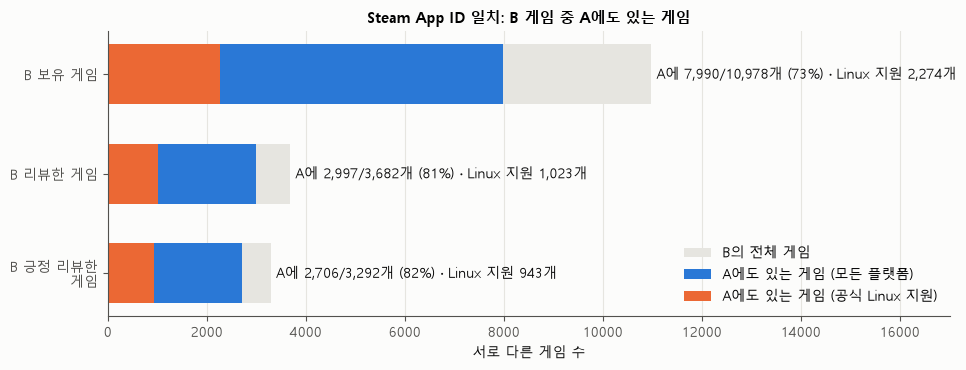

In [19]:
fig, ax = plt.subplots(figsize=(10, 3.8))
labels = ["B 보유 게임", "B 리뷰한 게임", "B 긍정 리뷰한\n게임"]
keys = ["B_owned_items", "B_review_items", "B_pos_review_items"]
tot = np.array([len(S[k]) for k in keys])
inA = np.array([len(S[k] & S["A_games"]) for k in keys])
inL = np.array([len(S[k] & S["A_linux"]) for k in keys])
y = np.arange(len(keys))[::-1]
ax.barh(y, tot, color=GRID, height=0.6, label="B의 전체 게임")
ax.barh(y, inA, color=BLUE, height=0.6, label="A에도 있는 게임 (모든 플랫폼)")
ax.barh(y, inL, color=ORANGE, height=0.6, label="A에도 있는 게임 (공식 Linux 지원)")
for yi, t, a, l in zip(y, tot, inA, inL):
    ax.text(t + tot.max() * 0.01, yi, f"A에 {a:,}/{t:,}개 ({a / t:.0%}) · Linux 지원 {l:,}개", va="center", color=INK)
ax.set_yticks(y, labels)
ax.set(title="Steam App ID 일치: B 게임 중 A에도 있는 게임", xlabel="서로 다른 게임 수", xlim=(0, tot.max() * 1.55))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
fig.tight_layout()
save_fig(fig, "fig04_id_overlap")

## 5. 별도 데이터로 평가할 수 있는지 확인 (A로 학습 → B의 신규 사용자에게 적용)

**평가 방법 (사용자별로 확인)**
- 평가용 정답(target): B의 `australian_user_reviews`에서 `recommend=True`인 리뷰 중 **A에서 공식 Linux 지원으로 표시된 게임**이다.
- 취향 입력(input): 같은 B 사용자(`user_id`로만 연결)가 `australian_users_items`에 보유한 게임 가운데 A에도 있는 게임이다.
- **정답이 입력에 섞이지 않도록 처리**: 입력에서 그 사용자가 리뷰한 게임을 긍정·부정 모두 제외한다. 리뷰한 게임은 보유 목록에도 대부분 있으므로(아래 확인), 제외하지 않으면 맞혀야 할 정답이 입력에 이미 들어간다.
- 추천할 수 있는 게임: A의 Linux 지원 게임 중 취향 입력에 포함되지 않은 게임이다. 보유·플레이 기록과 긍정 리뷰는 서로 다른 정보로 다룬다.

B 리뷰를 이용해 A 모델을 다시 학습하지 않는다. A에서 학습한 추천 방식을 B의 신규 사용자에게 적용하는 경우만 살펴본다.

In [20]:
# B 자료 정리: 중복 프로필은 사용자별 첫 행만 사용한다(1-1에서 게임 목록이 같은지 확인). 같은 사용자·게임의 중복 리뷰는 하나로 합치고, 긍정·부정 표시가 충돌하는 게임은 제외한다.
first_line = B_prof.groupby("user_id").line_no.min()
Bi = (B_items[B_items.line_no.isin(first_line.values)]
      .drop_duplicates(["user_id", "item_id"])[["user_id", "item_id", "playtime_forever"]])
conf_pairs = conflict[conflict].reset_index()[["user_id", "item_id"]]
Br = (B_rev.dropna(subset=["item_id"]).drop_duplicates(["user_id", "item_id", "recommend"])
      .merge(conf_pairs.assign(_c=1), on=["user_id", "item_id"], how="left"))
Br = Br[Br._c.isna()].drop(columns="_c")

owned_pairs = set(zip(Bi.user_id, Bi.item_id))
Br["owned"] = [(u, i) in owned_pairs for u, i in zip(Br.user_id, Br.item_id)]
rec("B_review_vs_ownership", {
    "review_users": Br.user_id.nunique(),
    "review_users_with_item_profile": int(Br.user_id.drop_duplicates().isin(Bi.user_id.unique()).sum()),
    "reviewed_items_also_owned_pct": float(Br.owned.mean() * 100),
    "positive_reviewed_items_also_owned_pct": float(Br.owned[Br.recommend].mean() * 100),
    "B_positive_rate": float(Br.recommend.mean()),
})
display(RESULTS["B_review_vs_ownership"])

,항목,값
0,리뷰를 쓴 사용자 수,"25,458"
1,그중 보유 목록이 있는 사용자 수,"22,613"
2,리뷰한 게임이 보유 목록에도 있는 비율(%),75.6208
3,긍정 리뷰한 게임이 보유 목록에도 있는 비율(%),75.9673
4,B 리뷰의 긍정 비율(0~1),0.8847


In [21]:
A_items = S["A_rec_items"]
cf_items = set(i_pos.index[i_pos >= 10])  # 협업 필터링에서 유사 게임을 찾을 최소 기준(긍정 리뷰 10명 이상)
L_all = lin_ids & A_items
L_cf = lin_ids & cf_items
rec("candidate_sets", {"A_linux_with_reviews": len(L_all), "A_linux_ge10_positive": len(L_cf),
                       "A_items_ge10_positive": len(cf_items)})

reviewed = Br.groupby("user_id").item_id.agg(set)
targets_all = Br[Br.recommend & Br.item_id.isin(L_all)].groupby("user_id").item_id.agg(set)

Bi_A = Bi[Bi.item_id.isin(A_items)]
inp_owned = Bi_A.groupby("user_id").item_id.agg(set)
inp_played = Bi_A[Bi_A.playtime_forever > 0].groupby("user_id").item_id.agg(set)

users = targets_all.index
ev = pd.DataFrame(index=users)
ev["targets"] = targets_all
ev["targets_cf"] = ev.targets.map(lambda t: t & L_cf)
rv = reviewed.reindex(users)
ev["input_owned"] = [(inp_owned.get(u, set()) - rv[u]) for u in users]
ev["input_played"] = [(inp_played.get(u, set()) - rv[u]) for u in users]
ev["input_owned_cf"] = ev.input_owned.map(lambda s: s & cf_items)
for c in ["targets", "targets_cf", "input_owned", "input_played", "input_owned_cf"]:
    ev["n_" + c] = ev[c].map(len)
assert all(not (t & i) for t, i in zip(ev.targets, ev.input_owned)), "leakage: target in input"

elig_rows = []
for inp in ["input_owned", "input_played", "input_owned_cf"]:
    for tgt in ["targets", "targets_cf"]:
        for k in [1, 2, 3, 5, 10, 20]:
            m = (ev["n_" + tgt] >= 1) & (ev["n_" + inp] >= k)
            elig_rows.append({"input": inp, "target": tgt, "min_input_items": k, "users": int(m.sum()),
                              "target_pairs": int(ev.loc[m, "n_" + tgt].sum()),
                              "unique_target_items": len(set().union(*ev.loc[m, tgt])) if m.any() else 0})
elig = save_table(pd.DataFrame(elig_rows), "05_external_test_eligibility")
rec("external_test_eligibility", elig_rows)
rec("external_test_main", {
    "users_with_linux_positive_target": int((ev.n_targets >= 1).sum()),
    "target_pairs": int(ev.n_targets.sum()), "unique_target_items": len(set().union(*ev.targets)),
    "targets_per_user": qtable(ev.n_targets),
    "users_with_ge2_targets": int((ev.n_targets >= 2).sum()),
    "input_owned_per_user": qtable(ev.n_input_owned),
    "eligible_users_k5_owned": int(((ev.n_targets >= 1) & (ev.n_input_owned >= 5)).sum()),
    "target_pairs_k5_owned": int(ev.n_targets[ev.n_input_owned >= 5].sum()),
    "target_pairs_that_are_cf_items_pct": float(ev.n_targets_cf.sum() / ev.n_targets.sum() * 100),
})
display(elig.pivot_table(index=["input", "min_input_items"], columns="target", values="users").reset_index().rename_axis(columns=None))

,입력 조건,사용자당 필요한 최소 입력 게임 수,정답: A의 Linux 긍정 게임,정답: 그중 협업 필터링 기준 충족 게임
0,보유 기록 기반 입력,1,"15,676.0000","15,676.0000"
1,보유 기록 기반 입력,2,"15,609.0000","15,609.0000"
2,보유 기록 기반 입력,3,"15,519.0000","15,519.0000"
3,보유 기록 기반 입력,5,"15,294.0000","15,294.0000"
4,보유 기록 기반 입력,10,"14,697.0000","14,697.0000"
5,보유 기록 기반 입력,20,"13,076.0000","13,076.0000"
6,보유 기록 기반 협업 필터링 입력,1,"15,676.0000","15,676.0000"
7,보유 기록 기반 협업 필터링 입력,2,"15,609.0000","15,609.0000"
8,보유 기록 기반 협업 필터링 입력,3,"15,518.0000","15,518.0000"
9,보유 기록 기반 협업 필터링 입력,5,"15,294.0000","15,294.0000"


In [22]:
# 다른 평가 방법(리뷰만 사용): B의 긍정 리뷰 중 하나를 맞힐 대상으로 남기고 나머지를 입력으로 삼는다. A 게임을 2개 이상 긍정 평가했고 그중 Linux 게임이 하나 이상인 사용자만 센다.
pos_A = Br[Br.recommend & Br.item_id.isin(A_items)].groupby("user_id").item_id.agg(set)
lo = pos_A[pos_A.map(len) >= 2]
rec("review_only_protocol", {"users_ge2_positive_in_A": len(lo),
                             "of_which_ge1_linux": int(lo.map(lambda s: len(s & L_all) >= 1).sum())})
display(RESULTS["review_only_protocol"])

,항목,값
0,A 게임 긍정 리뷰가 2건 이상인 B 사용자 수,"9,771"
1,그중 Linux 게임 긍정 리뷰가 있는 사용자 수,"8,771"


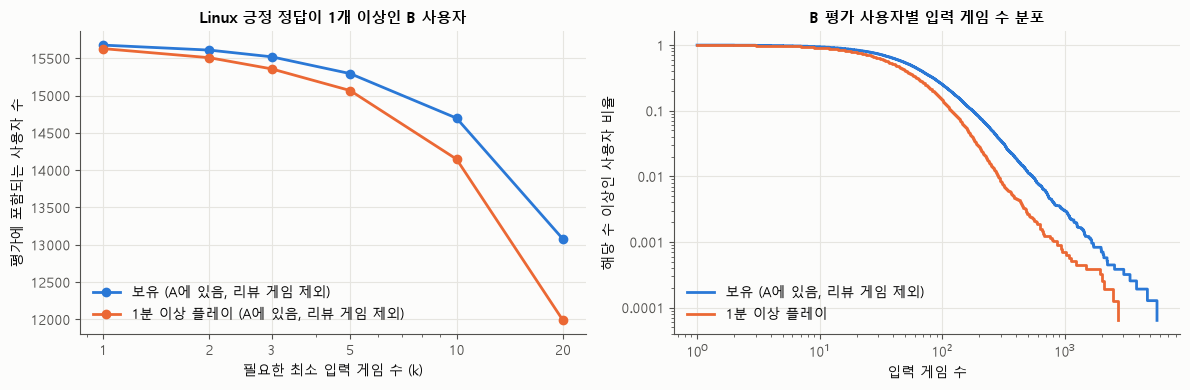

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# `input_owned_cf`와 `input_owned`는 거의 같아(입력 게임의 99.6%가 협업 필터링 기준을 충족) 선이 겹치므로 하나만 표시한다.
for inp, col, lab in [("input_owned", BLUE, "보유 (A에 있음, 리뷰 게임 제외)"),
                      ("input_played", ORANGE, "1분 이상 플레이 (A에 있음, 리뷰 게임 제외)")]:
    d = elig[(elig.input == inp) & (elig.target == "targets")]
    axes[0].plot(d.min_input_items, d.users, marker="o", ms=6, color=col, label=lab)
axes[0].set(xscale="log", title="Linux 긍정 정답이 1개 이상인 B 사용자", xlabel="필요한 최소 입력 게임 수 (k)",
            ylabel="평가에 포함되는 사용자 수")
axes[0].set_xticks([1, 2, 3, 5, 10, 20], ["1", "2", "3", "5", "10", "20"])
axes[0].legend()
ccdf(axes[1], ev.n_input_owned[ev.n_input_owned > 0].values, "보유 (A에 있음, 리뷰 게임 제외)", BLUE)
ccdf(axes[1], ev.n_input_played[ev.n_input_played > 0].values, "1분 이상 플레이", ORANGE)
axes[1].set(title="B 평가 사용자별 입력 게임 수 분포", xlabel="입력 게임 수", ylabel="해당 수 이상인 사용자 비율")
axes[1].legend()
fig.tight_layout()
save_fig(fig, "fig05_external_test_eligibility")

### 5-1. 인기도와 시점 차이, 인기순 간단 기준 점검
모델을 비교하기 전에 **평가 절차가 동작하는지** 살펴본다. 여기서 기준선은 A에서 긍정 리뷰가 많은 게임부터 추천하는 간단한 방법이다. 인기도 계산에는 A의 Linux 긍정 리뷰 수만 쓰며, B 정보는 쓰지 않는다.
아래의 Spearman 순위 상관계수(ρ)는 두 데이터에서 게임의 인기도 순위가 얼마나 비슷한지 나타낸다.

,항목,값
0,비교한 Linux 게임 수,"6,618"
1,A 긍정 리뷰 수와 B 긍정 리뷰 수의 순위 상관,0.4583
2,A 긍정 리뷰 수와 B 보유자 수의 순위 상관,0.4245
3,2015년까지의 A 긍정 리뷰 수와 B 긍정 리뷰 수의 순위 상관,0.6502


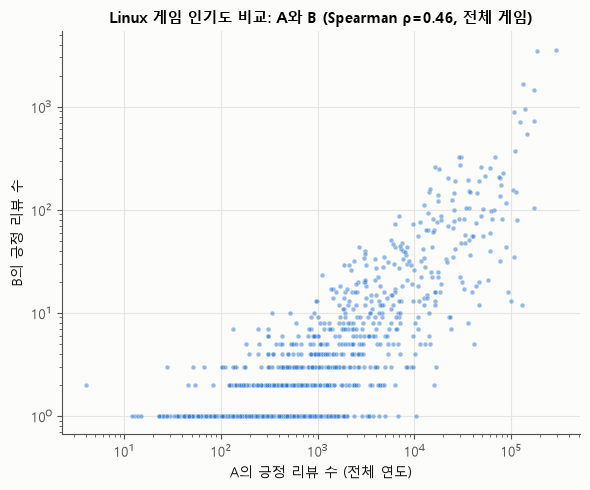

In [24]:
pop_A = lin_pos_item  # A Linux 긍정 리뷰 수
B_pos_cnt = Br[Br.recommend & Br.item_id.isin(L_all)].groupby("item_id").size()
B_own_cnt = Bi[Bi.item_id.isin(L_all)].groupby("item_id").size()
common = pd.DataFrame({"A_pos": pop_A, "B_pos": B_pos_cnt, "B_owners": B_own_cnt}).dropna(subset=["A_pos"]).fillna(0)
rho_pos = stats.spearmanr(common.A_pos, common.B_pos).statistic
rho_own = stats.spearmanr(common.A_pos, common.B_owners).statistic
A_pre = A_rec[(A_rec.date <= "2015-12-31") & A_rec.is_linux & A_rec.is_recommended].groupby("app_id").size()
rho_pre = stats.spearmanr(A_pre.reindex(common.index, fill_value=0), common.B_pos).statistic
rec("popularity_shift", {"linux_items_compared": len(common), "spearman_A_pos_vs_B_pos": float(rho_pos),
                         "spearman_A_pos_vs_B_owners": float(rho_own),
                         "spearman_A_pos_le2015_vs_B_pos": float(rho_pre)})

fig, ax = plt.subplots(figsize=(6, 5))
c2 = common[common.B_pos > 0]
ax.scatter(c2.A_pos, c2.B_pos, s=12, alpha=0.5, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
ax.set(xscale="log", yscale="log", xlabel="A의 긍정 리뷰 수 (전체 연도)", ylabel="B의 긍정 리뷰 수",
       title=f"Linux 게임 인기도 비교: A와 B (Spearman ρ={rho_pos:.2f}, 전체 게임)")
fig.tight_layout()
save_fig(fig, "fig06_popularity_A_vs_B")
display(RESULTS["popularity_shift"])

In [25]:
def eval_topk(ev_df, scores, k=10, input_col="input_owned", target_col="targets"):
    order = scores.sort_values(ascending=False).index.to_numpy()
    rec_, ndcg_ = [], []
    disc = 1 / np.log2(np.arange(2, k + 2))
    for inp, tgt in zip(ev_df[input_col], ev_df[target_col]):
        top = [i for i in order[: k + len(inp)] if i not in inp][:k]
        hits = np.array([i in tgt for i in top], dtype=float)
        rec_.append(hits.sum() / len(tgt))
        ndcg_.append((hits * disc[: len(hits)]).sum() / disc[: min(len(tgt), k)].sum())
    return float(np.mean(rec_)), float(np.mean(ndcg_))


sub = ev[(ev.n_targets >= 1) & (ev.n_input_owned >= 5)]
released_le2015 = set(A_games.app_id[A_games.date_release <= "2015-12-31"])
pop_le2015 = pop_A[pop_A.index.isin(released_le2015)]
base = {}
for name, sc in [("pop_A_all_linux", pop_A), ("pop_A_linux_released_le2015", pop_le2015),
                 ("pop_A_reviews_le2015", A_pre)]:
    r, nd = eval_topk(sub, sc)
    base[name] = {"recall@10": r, "ndcg@10": nd, "candidates": len(sc)}
base["random_expected_recall@10"] = {"recall@10": 10 / len(L_all), "candidates": len(L_all)}
rec("popularity_baseline_sanity", {"users": len(sub), **base})
display(RESULTS["popularity_baseline_sanity"])

,항목,값
0,사용자 수,"15,294"
1,"인기순: A 전체 기간, 전체 Linux 후보 / Recall@10",0.5386
2,"인기순: A 전체 기간, 전체 Linux 후보 / NDCG@10",0.3731
3,"인기순: A 전체 기간, 전체 Linux 후보 / 후보 수","6,618"
4,인기순: 2015년까지 출시된 Linux 후보 / Recall@10,0.5466
5,인기순: 2015년까지 출시된 Linux 후보 / NDCG@10,0.3769
6,인기순: 2015년까지 출시된 Linux 후보 / 후보 수,"1,521"
7,인기순: 2015년까지의 A 리뷰 사용 / Recall@10,0.5860
8,인기순: 2015년까지의 A 리뷰 사용 / NDCG@10,0.3837
9,인기순: 2015년까지의 A 리뷰 사용 / 후보 수,"1,649"


### 5-2. 정답이 인기 게임에 몰리는 정도와 덜 알려진 게임 평가
인기순 기준이 좋은 점수를 얻는 이유를 확인한다. 정답이 소수의 인기 게임에 몰리면 개인화 추천이 이를 넘기 어렵고, 평가는 사실상 "인기 게임 맞히기"가 된다.
A에서 긍정 리뷰가 가장 많은 Linux 게임 50개(인기 상위)를 제외하고, 그 밖의 상대적으로 덜 알려진 게임(롱테일)을 맞히는 성능도 살펴본다.
Recall@10은 추천 상위 10개에 정답 게임이 얼마나 포함됐는지, NDCG@10은 정답이 상위에 올수록 더 높게 점수를 주는 지표다.

In [26]:
tgt_cnt = pd.Series([i for s in sub.targets for i in s]).value_counts()
top_tgt = pd.DataFrame({"target_pairs": tgt_cnt.head(15), "share": tgt_cnt.head(15) / tgt_cnt.sum(),
                        "A_linux_pos_rank": pop_A.rank(ascending=False).reindex(tgt_cnt.head(15).index),
                        "title": A_games.set_index("app_id").title.reindex(tgt_cnt.head(15).index)})
save_table(top_tgt.rename_axis("app_id").reset_index(), "05_top_target_items")

HEAD_N = 50
head = set(pop_A.index[:HEAD_N])
sub_lt = sub.assign(targets=sub.targets.map(lambda s: s - head))
sub_lt = sub_lt[sub_lt.targets.map(len) > 0]
r_full, nd_full = eval_topk(sub_lt, pop_A)                       # 후보 전체, 롱테일 정답
r_tail, nd_tail = eval_topk(sub_lt, pop_A[~pop_A.index.isin(head)])  # 인기 상위 게임 50개를 추천 후보에서도 제외
rec("target_concentration", {
    "top3_items_share": float(tgt_cnt.head(3).sum() / tgt_cnt.sum()),
    "top10_items_share": float(tgt_cnt.head(10).sum() / tgt_cnt.sum()),
    "targets_in_A_top50_linux_share": float(tgt_cnt[tgt_cnt.index.isin(head)].sum() / tgt_cnt.sum()),
    "longtail_users": len(sub_lt), "longtail_target_pairs": int(sub_lt.targets.map(len).sum()),
    "longtail_unique_items": len(set().union(*sub_lt.targets)),
    "pop_recall@10_longtail_targets_full_candidates": r_full,
    "pop_recall@10_longtail_targets_head_excluded": r_tail, "pop_ndcg@10_longtail_head_excluded": nd_tail,
})
display(top_tgt)
display(RESULTS["target_concentration"])

,정답 사용자-게임 쌍 수,전체 정답 쌍 중 비중(0~1),A Linux 게임의 긍정 리뷰 순위,게임 제목
440,3072,0.1244,1.0000,Team Fortress 2
730,3048,0.1234,2.0000,Counter-Strike: Global Offensive
4000,1482,0.0600,8.0000,Garry's Mod
570,1243,0.0503,4.0000,Dota 2
304930,833,0.0337,7.0000,Unturned
218620,797,0.0323,16.0000,PAYDAY 2
550,631,0.0255,3.0000,Left 4 Dead 2
105600,628,0.0254,11.0000,Terraria
49520,474,0.0192,6.0000,Borderlands 2
620,323,0.0131,14.0000,Portal 2


,항목,값
0,상위 3개 게임이 차지하는 정답 비중(0~1),0.3077
1,상위 10개 게임이 차지하는 정답 비중(0~1),0.5072
2,A 인기 상위 50개 Linux 게임이 차지하는 정답 비중(0~1),0.6403
3,인기 상위 50개를 뺀 평가의 사용자 수,"6,533"
4,인기 상위 50개를 뺀 평가의 정답 쌍 수,"8,885"
5,인기 상위 50개를 뺀 평가의 정답 게임 수,786
6,인기순 Recall@10(상위 50개를 정답에서만 뺌),0
7,인기순 Recall@10(상위 50개를 정답과 후보에서 뺌),0.0320
8,인기순 NDCG@10(상위 50개를 정답과 후보에서 뺌),0.0143


## 6. 신규 사용자에게 협업 필터링을 적용할 수 있는지
- B의 평가 사용자는 A에서 본 적 없는 **신규 사용자**다. 사용자끼리의 이력을 이용하는 방식은 A에서 학습한 사용자별 취향 정보가 없어 그대로 쓸 수 없다.
- 게임끼리의 이력을 이용하는 KNN(가까운 이웃 찾기) 방식은 입력 게임과 비슷한 게임을 A에서 찾아 신규 사용자에게도 적용할 수 있다. 다만 입력 게임은 A에서 긍정 리뷰가 10건 이상 있어야 비교할 이력이 충분하다고 본다.
- implicit ALS(보유·긍정 기록을 이용하는 ALS)는 A에서 학습한 게임별 벡터를 고정하고, 신규 사용자 이력에 맞춰 사용자 벡터를 한 번 계산하는 절차(fold-in)가 필요하다.

In [27]:
lin_cf_tgt = ev.n_targets_cf.sum() / ev.n_targets.sum()
rec("new_user_cf", {
    "A_users_lt5_positive_pct": float((u_pos.reindex(u_cnt.index, fill_value=0) < 5).mean() * 100),
    "B_test_users_with_0_cf_input": int((ev.n_input_owned_cf == 0).sum()),
    "B_test_users_with_ge5_cf_input": int((ev.n_input_owned_cf >= 5).sum()),
    "B_test_users": len(ev),
    "B_input_items_cf_share_pct": float(ev.n_input_owned_cf.sum() / max(ev.n_input_owned.sum(), 1) * 100),
    "B_targets_reachable_by_itemknn_pct": float(lin_cf_tgt * 100),
    "B_input_cf_per_user": qtable(ev.n_input_owned_cf),
})
display(RESULTS["new_user_cf"])

,항목,값
0,긍정 리뷰가 5건 미만인 A 사용자 비율(%),88.2152
1,협업 필터링 입력이 없는 B 사용자 수,"1,900"
2,협업 필터링 입력이 5개 이상인 B 사용자 수,"15,294"
3,Linux 정답이 있는 B 사용자 수,"17,576"
4,입력 게임 중 협업 필터링에 쓸 수 있는 비율(%),99.5927
5,정답 중 협업 필터링 후보에 있는 비율(%),99.9928
6,B 사용자별 협업 필터링 입력 게임 수 / 하위 25% 값,19
7,B 사용자별 협업 필터링 입력 게임 수 / 중앙값,46
8,B 사용자별 협업 필터링 입력 게임 수 / 하위 75% 값,91
9,B 사용자별 협업 필터링 입력 게임 수 / 하위 90% 값,163


## 7. 결과 저장

In [28]:
(REP / "eda_metrics.json").write_text(json.dumps(RESULTS, indent=2, ensure_ascii=False, default=str), "utf-8")
print("저장 완료:", REP / "eda_metrics.json", "결과 항목 수:", len(RESULTS))
print("생성한 차트 파일:", sorted(p.name for p in FIG.glob("*.png")))

저장 완료: E:\Development\Projects\ML-game-recommendation\EDA\reports\eda_metrics.json 결과 항목 수: 27
생성한 차트 파일: ['fig01_A_interactions_hours.png', 'fig02_reviews_by_year.png', 'fig03_A_linux_share_concentration.png', 'fig04_id_overlap.png', 'fig05_external_test_eligibility.png', 'fig06_popularity_A_vs_B.png', 'fig07_label_sufficiency.png', 'fig08_cooccurrence_support.png', 'fig09_A_linux_top_tags.png', 'fig10_tfidf_nearest_similarity.png', 'fig11_B_input_loss.png', 'fig12_tag_source_weighted.png']
